# Transformer Modelling: RoBERTa-base

This notebook implements a transformer-based sequence classification model using RoBERTa-base.

The objective is to compare contextual transformer representations against the classical TF-IDF + Logistic Regression baseline. Since RoBERTa captures semantic and contextual relationships through self-attention, it is expected to provide stronger performance, particularly on linguistically complex tasks.

## Imports

In [16]:
import os
import numpy as np
import pandas as pd
import evaluate

from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

## Data Loading

The predefined train, validation, and test splits are loaded from the locally stored BESSTIE files. The test set remains strictly held out until final evaluation.

In [17]:
base_path = "../data/raw"

train_df = pd.read_csv(os.path.join(base_path, "besstie_train.csv"))
val_df = pd.read_csv(os.path.join(base_path, "besstie_validation.csv"))
test_df = pd.read_csv(os.path.join(base_path, "besstie_test.csv"))

print("Train shape:", train_df.shape)
print("Validation shape:", val_df.shape)
print("Test shape:", test_df.shape)

Train shape: (3747, 5)
Validation shape: (313, 5)
Test shape: (2183, 5)


## Task Definition

We begin with sentiment classification in order to establish a fair transformer comparison against the classical baseline.

In [18]:
TEXT_COL = "text"
LABEL_COL = "Sentiment"

train_data = train_df[[TEXT_COL, LABEL_COL]].copy()
val_data = val_df[[TEXT_COL, LABEL_COL]].copy()
test_data = test_df[[TEXT_COL, LABEL_COL]].copy()

train_data.columns = ["text", "label"]
val_data.columns = ["text", "label"]
test_data.columns = ["text", "label"]

train_data["label"] = train_data["label"].astype(int)
val_data["label"] = val_data["label"].astype(int)
test_data["label"] = test_data["label"].astype(int)

train_data.head()

,text,label
0,I'm a member of the Green Party but I'll be vo...,0
1,Yeah it blew out to 3x what it was budgeted fo...,0
2,"Food was pretty great. A little dry, but I am ...",1
3,Firstly the staff seemed as if they did n't wa...,0
4,We came for lunch and enjoyed the food we orde...,1


In [19]:
# Converting pandas to Huggingface Dataset 

from datasets import Dataset

train_dataset = Dataset.from_pandas(train_data, preserve_index=False)
val_dataset = Dataset.from_pandas(val_data, preserve_index=False)
test_dataset = Dataset.from_pandas(test_data, preserve_index=False)

print(train_dataset.features)


{'text': Value('large_string'), 'label': Value('int64')}


## Tokenisation

RoBERTa uses subword tokenisation, which enables it to handle lexical variation more effectively than classical frequency-based methods.

In [20]:
model_name = "roberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)

In [21]:
# Function 

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        padding="max_length",
        max_length=128
    )

In [22]:
tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val = val_dataset.map(tokenize_function, batched=True)
tokenized_test = test_dataset.map(tokenize_function, batched=True)

tokenized_train = tokenized_train.remove_columns(["text"])
tokenized_val = tokenized_val.remove_columns(["text"])
tokenized_test = tokenized_test.remove_columns(["text"])

tokenized_train.set_format("torch")
tokenized_val.set_format("torch")
tokenized_test.set_format("torch")

print(tokenized_train[0])

Map: 100%|██████████| 2183/2183 [00:00<00:00, 14731.04 examples/s]

{'label': tensor(0), 'input_ids': tensor([    0,   100,   437,    10,   919,     9,     5,  1628,  1643,    53,
           38,   581,    28,  3434, 11135,  5245,    25,    24,    18,    98,
         3229,   259,   227, 11135,  5245,     8, 10886,     4,    38,  1395,
        32848,    84, 23584, 13515,     9,    10, 10886,  3957,   145,   769,
        15672,     4,    38,   581,   304,     5, 38870,  1308, 17768,   998,
           98,   951,  6152,    64,   900,  1628,    13,   162,     4,     2,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,     1,     1,     1,     1,     1,     1,     1,
            1,     1,     1,  

In [23]:
tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val = val_dataset.map(tokenize_function, batched=True)
tokenized_test = test_dataset.map(tokenize_function, batched=True)

Map: 100%|██████████| 2183/2183 [00:00<00:00, 16405.49 examples/s]


In [24]:
# Removing unused columns and setting format 

tokenized_train = tokenized_train.remove_columns(["text"])
tokenized_val = tokenized_val.remove_columns(["text"])
tokenized_test = tokenized_test.remove_columns(["text"])

tokenized_train.set_format("torch")
tokenized_val.set_format("torch")
tokenized_test.set_format("torch")

# Loading Model 

In [25]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

model.config.problem_type = "single_label_classification"

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 1214.38it/s, Materializing param=roberta.encoder.layer.11.output.dense.weight]              
RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consid

## Evaluation Metrics

Macro-F1 is used as the primary metric to ensure balanced evaluation across both classes.

In [26]:
accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")
precision_metric = evaluate.load("precision")
recall_metric = evaluate.load("recall")

In [27]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_metric.compute(predictions=predictions, references=labels)["accuracy"]
    macro_f1 = f1_metric.compute(predictions=predictions, references=labels, average="macro")["f1"]
    precision = precision_metric.compute(predictions=predictions, references=labels, average="macro")["precision"]
    recall = recall_metric.compute(predictions=predictions, references=labels, average="macro")["recall"]

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "precision": precision,
        "recall": recall
    }

## Training Arguments

In [28]:
training_args = TrainingArguments(
    output_dir="../results/checkpoints/roberta_sentiment",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    report_to="none"
)

In [29]:
# Trainer 

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics
)

## Model Training

The RoBERTa-base model is fine-tuned on the sentiment classification task using the predefined training split.

In [30]:
trainer.train()

c:\Users\resha\anaconda4\envs\myenv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Precision,Recall
1,0.402366,0.212975,0.913738,0.913738,0.914195,0.914195
2,0.255796,0.270217,0.936102,0.936086,0.936035,0.936213


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.47it/s]
c:\Users\resha\anaconda4\envs\myenv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.32it/s]
There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.we

TrainOutput(global_step=938, training_loss=0.32908091107919524, metrics={'train_runtime': 2097.092, 'train_samples_per_second': 3.574, 'train_steps_per_second': 0.447, 'total_flos': 492938562216960.0, 'train_loss': 0.32908091107919524, 'epoch': 2.0})

## Validation Evaluation

After training, the fine-tuned RoBERTa model is evaluated on the validation split in order to measure performance before final testing.

In [31]:
val_results = trainer.evaluate(tokenized_val)
val_results

c:\Users\resha\anaconda4\envs\myenv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


{'eval_loss': 0.27021723985671997,
 'eval_accuracy': 0.9361022364217252,
 'eval_macro_f1': 0.9360859266519643,
 'eval_precision': 0.9360351163740303,
 'eval_recall': 0.9362132352941177,
 'eval_runtime': 19.8113,
 'eval_samples_per_second': 15.799,
 'eval_steps_per_second': 2.019,
 'epoch': 2.0}

## Test Evaluation

The final sentiment model is evaluated on the held-out test split. This allows a fair comparison against the classical baseline.

In [32]:
test_results = trainer.evaluate(tokenized_test)
test_results

c:\Users\resha\anaconda4\envs\myenv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


{'eval_loss': 0.4439639151096344,
 'eval_accuracy': 0.8886852954649564,
 'eval_macro_f1': 0.8886829595653156,
 'eval_precision': 0.8889296064583943,
 'eval_recall': 0.8890635261631179,
 'eval_runtime': 137.9512,
 'eval_samples_per_second': 15.824,
 'eval_steps_per_second': 1.979,
 'epoch': 2.0}

## Saving Test results

In [33]:
results_df = pd.DataFrame({
    "model": ["RoBERTa-base"],
    "task": ["Sentiment"],
    "validation_macro_f1": [val_results["eval_macro_f1"]],
    "test_macro_f1": [test_results["eval_macro_f1"]],
    "validation_precision": [val_results["eval_precision"]],
    "test_precision": [test_results["eval_precision"]],
    "validation_recall": [val_results["eval_recall"]],
    "test_recall": [test_results["eval_recall"]],
    "validation_accuracy": [val_results["eval_accuracy"]],
    "test_accuracy": [test_results["eval_accuracy"]]
})

results_path = "../results/tables/roberta_sentiment_results.csv"
results_df.to_csv(results_path, index=False)

print(f"Saved results to: {results_path}")
results_df

Saved results to: ../results/tables/roberta_sentiment_results.csv


,model,task,validation_macro_f1,test_macro_f1,validation_precision,test_precision,validation_recall,test_recall,validation_accuracy,test_accuracy
0,RoBERTa-base,Sentiment,0.936086,0.888683,0.936035,0.88893,0.936213,0.889064,0.936102,0.888685


## Comparison with Classical Baseline

To assess the value of contextual representations, the transformer model is compared directly against the TF-IDF + Logistic Regression baseline.

In [34]:
baseline_df = pd.read_csv("../results/tables/baseline_sentiment_results.csv")
roberta_df = pd.read_csv("../results/tables/roberta_sentiment_results.csv")

comparison_df = pd.concat([baseline_df, roberta_df], ignore_index=True)
comparison_df

,model,task,validation_macro_f1,test_macro_f1,validation_precision,test_precision,validation_recall,test_recall,validation_accuracy,test_accuracy
0,TF-IDF + Logistic Regression,Sentiment,0.843348,0.819186,0.843413,0.820016,0.843301,0.818966,NaN,NaN
1,RoBERTa-base,Sentiment,0.936086,0.888683,0.936035,0.888930,0.936213,0.889064,0.936102,0.888685


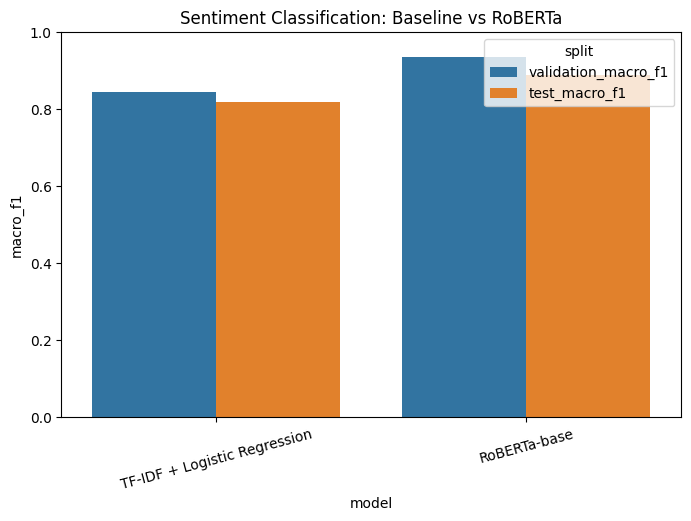

In [37]:
# Comparision Plot 
import matplotlib.pyplot as plt 
import seaborn as sns

plot_df = comparison_df[["model", "validation_macro_f1", "test_macro_f1"]].copy()
plot_df = plot_df.melt(id_vars="model", var_name="split", value_name="macro_f1")

plt.figure(figsize=(8,5))
sns.barplot(data=plot_df, x="model", y="macro_f1", hue="split")
plt.title("Sentiment Classification: Baseline vs RoBERTa")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.show()

## Interpretation of Sentiment Results

#### Sentiment Classification Performance - Baseline vs RoBERTa

Figure 1 presents a comparison between the classical TF-IDF + Logistic Regression baseline and the RoBERTa-base transformer model on the sentiment classification task.

The results show a clear improvement when using the transformer-based approach. While the baseline achieves a test Macro-F1 score of approximately 0.82, RoBERTa achieves a significantly higher test Macro-F1 score of approximately 0.89.

This improvement highlights the advantage of contextual representations. The TF-IDF model relies on surface-level token frequencies and performs well when sentiment is explicitly expressed through words. However, RoBERTa captures contextual relationships between words, allowing it to better interpret nuanced expressions and sentence structure.

The relatively small gap between validation and test performance for both models indicates stable generalisation. However, the transformer model consistently outperforms the baseline across all metrics, demonstrating its superior capability for sequence classification in this setting.

# Transformer Modelling: Sarcasm Detection

In this section, the RoBERTa-base model is fine-tuned on the sarcasm detection task. This experiment is particularly important because sarcasm depends heavily on context and implicit meaning, making it a more suitable task for transformer-based models than for classical TF-IDF baselines.

## Defining sarcasm and Recreating Dataset 

In [38]:
LABEL_COL = "Sarcasm"

train_data = train_df[["text", LABEL_COL]].copy()
val_data = val_df[["text", LABEL_COL]].copy()
test_data = test_df[["text", LABEL_COL]].copy()

train_data.columns = ["text", "label"]
val_data.columns = ["text", "label"]
test_data.columns = ["text", "label"]

train_data["label"] = train_data["label"].astype(int)
val_data["label"] = val_data["label"].astype(int)
test_data["label"] = test_data["label"].astype(int)

In [39]:
train_dataset = Dataset.from_pandas(train_data, preserve_index=False)
val_dataset = Dataset.from_pandas(val_data, preserve_index=False)
test_dataset = Dataset.from_pandas(test_data, preserve_index=False)

print(train_dataset.features)

{'text': Value('large_string'), 'label': Value('int64')}


## Tokenization 

In [40]:
tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val = val_dataset.map(tokenize_function, batched=True)
tokenized_test = test_dataset.map(tokenize_function, batched=True)

tokenized_train = tokenized_train.remove_columns(["text"])
tokenized_val = tokenized_val.remove_columns(["text"])
tokenized_test = tokenized_test.remove_columns(["text"])

tokenized_train.set_format("torch")
tokenized_val.set_format("torch")
tokenized_test.set_format("torch")

Map: 100%|██████████| 2183/2183 [00:00<00:00, 15421.46 examples/s]


## Model Loading 

In [41]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2
)

model.config.problem_type = "single_label_classification"

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 877.67it/s, Materializing param=roberta.encoder.layer.11.output.dense.weight]              
RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.out_proj.bias        | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Conside

## Training Arguments 

In [42]:
training_args = TrainingArguments(
    output_dir="../results/checkpoints/roberta_sarcasm",
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    report_to="none"
)

## Training Model 

In [43]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    compute_metrics=compute_metrics
)

In [44]:
trainer.train()

c:\Users\resha\anaconda4\envs\myenv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Precision,Recall
1,0.374942,0.387662,0.859425,0.462199,0.429712,0.500000
2,0.301107,0.367176,0.856230,0.633518,0.684444,0.612200


c:\Users\resha\anaconda4\envs\myenv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.32it/s]
c:\Users\resha\anaconda4\envs\myenv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  2.37it/s]
There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNo

TrainOutput(global_step=938, training_loss=0.3380243427463686, metrics={'train_runtime': 2133.2709, 'train_samples_per_second': 3.513, 'train_steps_per_second': 0.44, 'total_flos': 492938562216960.0, 'train_loss': 0.3380243427463686, 'epoch': 2.0})

## Validation Evaluation 

In [45]:
val_results = trainer.evaluate(tokenized_val)
val_results

c:\Users\resha\anaconda4\envs\myenv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


{'eval_loss': 0.3671760559082031,
 'eval_accuracy': 0.8562300319488818,
 'eval_macro_f1': 0.6335180704082429,
 'eval_precision': 0.6844444444444444,
 'eval_recall': 0.6122000675904021,
 'eval_runtime': 20.9301,
 'eval_samples_per_second': 14.955,
 'eval_steps_per_second': 1.911,
 'epoch': 2.0}

## Test Evaluation 

In [46]:
test_results = trainer.evaluate(tokenized_test)
test_results

c:\Users\resha\anaconda4\envs\myenv\Lib\site-packages\torch\utils\data\dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


{'eval_loss': 0.3368285000324249,
 'eval_accuracy': 0.8685295464956482,
 'eval_macro_f1': 0.655915177284243,
 'eval_precision': 0.7245862884160756,
 'eval_recall': 0.6283716545330749,
 'eval_runtime': 139.5473,
 'eval_samples_per_second': 15.643,
 'eval_steps_per_second': 1.956,
 'epoch': 2.0}

## Interpretation of Sarcasm Results

The transformer model shows a substantial improvement over the TF-IDF baseline on sarcasm detection. While the TF-IDF model achieves a test Macro-F1 score of approximately 0.46 and fails to detect sarcastic instances effectively, RoBERTa improves performance to approximately 0.66.

This improvement demonstrates the importance of contextual understanding for sarcasm detection. Unlike sentiment classification, sarcasm often involves a mismatch between literal word meaning and intended interpretation. As a result, models that rely on surface-level token frequency struggle to identify sarcastic expressions.

RoBERTa, on the other hand, leverages self-attention mechanisms to capture relationships between words within a sentence. This allows the model to detect patterns such as contrast and implicit meaning, which are essential for identifying sarcasm.

Although the transformer model does not achieve perfect performance, the significant improvement over the baseline confirms that contextual representations are crucial for handling linguistically complex tasks.

## Comparison: Baseline vs Transformer Across Tasks

The experimental results reveal a clear distinction between the capabilities of classical and transformer-based models.

For sentiment classification, both models perform relatively well, although RoBERTa provides a noticeable improvement. This is expected, as sentiment is often expressed through explicit lexical cues that can be captured by TF-IDF.

However, for sarcasm detection, the difference is much more pronounced. The TF-IDF model fails to detect sarcastic instances, resulting in a very low Macro-F1 score. In contrast, RoBERTa significantly improves performance by capturing contextual and semantic relationships.

This contrast highlights a key limitation of classical NLP approaches: their reliance on surface-level features. Transformer models overcome this limitation by modelling context, making them more suitable for tasks involving implicit meaning and linguistic nuance.

Overall, the results demonstrate that while classical models can serve as strong baselines, transformer-based models provide a more robust and generalisable framework for NLP tasks, particularly those requiring contextual understanding.